# 移动 Web 第一天

平面转换、渐变（前端第11天）


## 本日目标与资料

本日目标是使用位移、缩放、旋转和渐变，丰富网页元素的呈现方式。课程先讲平面转换及其案例，再讲线性、径向渐变，最后在喜马拉雅页面中组合使用这些效果。

本篇仍放在现有 `01-HTML+CSS` 目录中。资料来自第一份分享中的 `移动Web-Day11资料.rar`：22页课件、配套Markdown与12页PDF笔记、XMind、课堂01～15示例，以及华为产品作业。

| 内容 | 核心属性 | 本日案例 |
| --- | --- | --- |
| 平移 | `transform: translate(...)` | 定位居中、双开门 |
| 旋转与原点 | `rotate(...)`、`transform-origin` | 风车、时钟、轮胎 |
| 缩放与倾斜 | `scale(...)`、`skew(...)` | 播放按钮、图片效果 |
| 渐变 | `linear-gradient(...)`、`radial-gradient(...)` | 产品遮罩、按钮高光 |
| 综合应用 | 转换、渐变、过渡配合 | 喜马拉雅、华为新闻卡片 |

课堂文件在 `移动Web-Day11资料/code/`。简单示例以下完整保留 `<style>` 与 `<body>` 中的教学代码，省去重复页面头部；综合案例与作业按文件保留。代码的图片路径以各自HTML所在目录为基准，不能把所有片段随意放进同一个文件后仍沿用原路径。

补充：部分演示在同一规则中连续写了多条 `transform` 或 `background-image`。它们用于比较写法，浏览器实际采用最后一条有效声明；每节都说明当前生效状态，不把这些声明理解为效果自动累加。


## 1. 平面转换

平面转换也叫2D转换：在X、Y两条坐标轴构成的平面内，改变元素的位置、角度、大小或倾斜形态。属性是 `transform`，常与 `transition`配合，让状态变化有过渡过程。

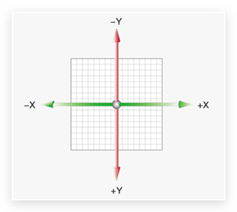

通常网页坐标中，X正方向向右、Y正方向向下；因此向左、向上的平移取负值。

补充：转换主要改变元素呈现的位置与形态，不重新安排它在普通文档流中的占位。移动或放大后可能覆盖相邻内容，不能把转换当成重新计算页面布局的宽高和间距。


### 1.1 先体验转换与过渡的配合

文件：`code/01-体验平面转换.html`。

CSS（放在 `<style>` 内）：

```css
div {
  margin: 100px 0;

  width: 100px;
  height: 100px;
  background-color: pink;

  transition: all 1s;
}

/* 鼠标滑过：添加动态效果 */
div:hover {
  transform: translate(800px) rotate(360deg) scale(2) skew(180deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

默认是100×100px粉色盒子。悬停后，一个 `transform`列表同时包含平移、旋转、缩放与倾斜；默认状态的 `transition: all 1s`使变化在1秒内完成，移开鼠标时也会回到初始状态。

先观察整体效果，再逐项理解函数。`translate(800px)`向右移动，`rotate(360deg)`旋转一圈，`scale(2)`放大两倍。

补充：`skew(180deg)`在最终状态与不倾斜等效；倾斜角在过渡中可能接近90deg等极端位置。这份文件用于体验组合效果，后面的单项示例更适合观察每个函数。


### 1.2 平移：百分比参照自身尺寸

基本写法：

```css
transform: translate(X轴移动距离, Y轴移动距离);
```

取值可以是带像素单位的数值或百分比，正负均可。只写一个值表示沿X轴平移；也可以分别用 `translateX(...)`、`translateY(...)`。

文件：`code/02-平移效果.html`。

CSS（放在 `<style>` 内）：

```css
.father {
    width: 500px;
    height: 300px;
    margin: 100px auto;
    border: 1px solid #000;
}

.son {
    width: 200px;
    height: 100px;
    background-color: pink;
    transition: all 0.5s;
}

/* 鼠标移入到父盒子，son改变位置 */
.father:hover .son {
    transform: translate(200px, 100px);

    /* 百分比：参照盒子自身尺寸计算结果 */
    transform: translate(50%, 100%);
    transform: translate(-50%, 100%);

    /* 只写一个数表示水平方向 */
    transform: translate(100px);

    transform: translateY(100px);
    transform: translateX(100px);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
    <div class="son"></div>
</div>
```

父盒子500×300px，子盒子200×100px，鼠标移入父盒子时改变子盒子。对这些声明分别观察：

| 声明 | 子盒子的位移 |
| --- | --- |
| `translate(200px, 100px)` | 右200px、下100px |
| `translate(50%, 100%)` | 右100px、下100px |
| `translate(-50%, 100%)` | 左100px、下100px |
| `translate(100px)` | 只向右100px |
| `translateY(100px)` | 只向下100px |
| `translateX(100px)` | 只向右100px |

百分比参照被转换的子盒子，而不是父盒子：X的50%是200×50%=100px，Y的100%是100px。

这份源码最后一条是 `transform: translateX(100px)`，所以直接打开后只会向右移动100px。若要比较前面写法，应每次只保留一条参与效果的声明。


### 1.3 绝对定位居中：父级一半减去自身一半

仅写 `left: 50%; top: 50%`，是把元素左上角放到定位参照区域的中点，不是把整个元素居中。原课比较两种回移方式。

方法一：已知200×100px尺寸，用负外边距回移宽高的一半。

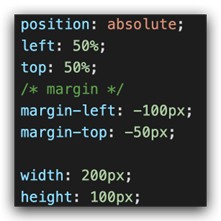

方法二：用 `translate(-50%, -50%)`回移自身宽高的一半，不必随盒子尺寸变化手工修改偏移。

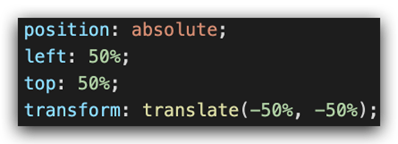

文件：`code/03-绝对定位元素居中.html`。

CSS（放在 `<style>` 内）：

```css
.box {
    position: absolute;
    left: 50%;
    top: 50%;

    /* 向左向上移动自身尺寸的一半 */
    transform: translate(-50%, -50%);

    width: 200px;
    height: 100px;
    background-color: pink;          
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box"></div>
```

关键是两组百分比参照不同：`left`、`top`相对于定位包含块，平移相对于元素自身。在200×100px例子里，平移量是左100px、上50px。

补充：此文件没有定位祖先，绝对定位参照初始包含块。若要在某个父盒子内部居中，应让该父盒子成为定位参照，例如设置 `position: relative`，再保留子元素的居中规则。

查看时粉色盒子的中心应落在参照区域的中点。以后给这个盒子再加其他转换时，须保留居中的平移函数，不能用另一条 `transform`把它覆盖。


### 1.4 双开门：两块封面各向外移动自身宽度

目标是鼠标移入后左右两块封面向外滑开，露出父盒子的背景。

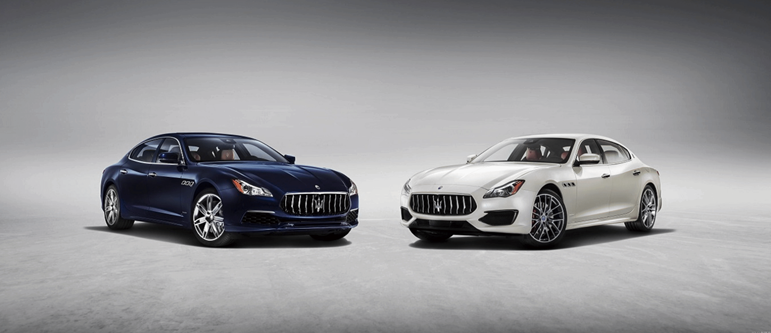

文件：`code/04-案例-双开门/demo.html`。

CSS（放在 `<style>` 内）：

```css
* {
    margin: 0;
    padding: 0;
}

/* 1. 布局：父子结构，父级是大图，子级是左右小图 */
.father {
    display: flex;
    margin: 0 auto;
    width: 1366px;
    height: 600px;
    background-image: url(./images/bg.jpg);

    overflow: hidden;
}

.father .left,
.father .right {
    width: 50%;
    height: 600px;
    background-image: url(./images/fm.jpg);

    transition: all .5s;
}

.father .right {
    /* right 表示的取到精灵图右面的图片 */
    background-position: right 0;
}

/* 2. 鼠标悬停的效果：左右移动 */
.father:hover .left {
    transform: translate(-100%);
}

.father:hover .right {
    transform: translateX(100%);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="father">
    <div class="left"></div>
    <div class="right"></div>
</div>
```

先建立父子结构：父盒子1366×600px，用 `bg.jpg`作为底图；两个子盒子各占50%宽度，高600px，共用 `fm.jpg`封面。`display: flex`在此把两块门排在同一行。

左门默认截取封面左边，右门使用 `background-position: right 0`截取右边，拼出完整封面。这里改变的是背景图片的显示位置，不是把右门盒子移动到右侧。

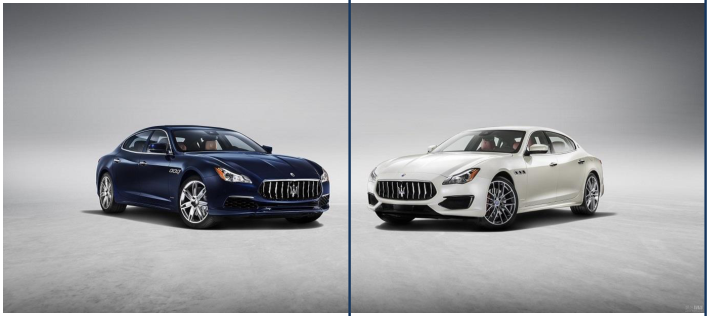

悬停规则写在父盒子上：左门 `translate(-100%)`，右门 `translateX(100%)`。每块门宽683px，所以各移动683px，恰好滑出父盒子范围。

父级 `overflow: hidden`裁掉移出的门；子级默认设置0.5秒过渡，使打开与关闭都有滑动过程。查看时鼠标进入整幅图，两块门同时向外移，鼠标离开后合拢。

补充：这是横向平移的“开门”效果，没有三维旋转。源码中的Flex只用于排布两块门，本日重点仍是位移和裁切。


### 1.5 旋转：角度用deg，正负决定方向

```css
transform: rotate(旋转角度);
```

原课在通常的网页方向下，正值顺时针，负值逆时针；角度单位为 `deg`。

文件：`code/05-旋转效果.html`。

CSS（放在 `<style>` 内）：

```css
img {
  width: 200px;
  transition: all 2s;
}

/* 鼠标悬停到图片上面，添加旋转效果 */
img:hover {
  /* 正数：顺时针旋转；负数：逆时针旋转 */
  transform: rotate(360deg);
  transform: rotate(-360deg);
}
```

HTML（放在 `<body>` 内）：

```html
<img src="./images/rotate.png" alt="">
```

图片宽200px，默认设置2秒过渡。源码连续写 `rotate(360deg)`与 `rotate(-360deg)`，后者生效：悬停时逆时针旋转一圈。

旋转一整圈后最终外观与开始相同，但过渡中可以看到旋转过程。没有过渡时，只看最终状态可能以为没有变化。


### 1.6 转换原点：改变绕哪个点旋转

默认转换原点是盒子中心。用 `transform-origin`设置水平与垂直位置，可以用方位名词、像素或百分比。

```css
transform-origin: 水平原点位置 垂直原点位置;
```

方位名词包括 `left`、`right`、`top`、`bottom`、`center`。例如 `center bottom`是底边中点，`right bottom`是右下角。

文件：`code/06-转换原点.html`。

CSS（放在 `<style>` 内）：

```css
img {
  width: 200px;
  border: 1px solid #000;
  transition: all 1s;

  transform-origin: right bottom;
}

img:hover {
  transform: rotate(360deg);
}
```

HTML（放在 `<body>` 内）：

```html
<img src="./images/rotate.png" alt="">
```

本例原点改为右下角。悬停后图片围绕这个角旋转一圈，右下角保持为旋转中心；边框帮助观察图片范围。

原点属性决定旋转、缩放等效果的支点，本身不会直接把元素移动到该位置。


### 1.7 时钟：刻度绕中心，表针绕底端

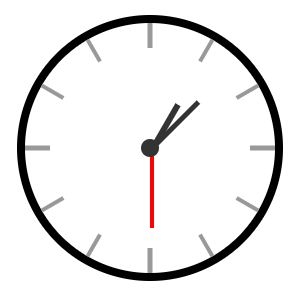

文件：`code/07-案例-时钟-转换原点.html`。

CSS（放在 `<style>` 内）：

```css
.clock {
  width: 250px;
  height: 250px;
  border: 8px solid #000;
  border-radius: 50%;
  margin: 100px auto;
  position: relative;
}

.line {
  /* 1.定位 */
  position: absolute;
  width: 4px;
  height: 250px;
  background-color: #999;
  left: 50%;
  transform: translate(-50%);
}

/* 线2: 旋转, 每条线旋转角度不同, 单独选中不同的line, 写rotate代码 */
/* 一圈是360度, 等分成  xx 份 */
.line:nth-child(2) {
  transform: translate(-50%) rotate(30deg);
}

.line:nth-child(3) {
  transform: translate(-50%) rotate(60deg);
}

.line:nth-child(4) {
  transform: translate(-50%) rotate(90deg);
}

.line:nth-child(5) {
  transform: translate(-50%) rotate(120deg);
}

.line:nth-child(6) {
  transform: translate(-50%) rotate(150deg);
}

/* 第一根和第四跟宽度大一些 */
.line:nth-child(1),
.line:nth-child(4) {
  width: 5px;
}

/* 遮罩圆形 */
.cover {
  position: absolute;
  left: 50%;
  top: 50%;
  transform: translate(-50%, -50%);
  width: 200px;
  height: 200px;
  background-color: #fff;
  border-radius: 50%;
}

/* 表针 */
/* 并集选择器放在单独选择器的上面, 避免transform属性的层叠 */
.hour,
.minute,
.second {
  position: absolute;
  left: 50%;
  /* 盒子底部在盒子中间 */
  bottom: 50%;
}

.hour {
  width: 6px;
  height: 50px;
  background-color: #333;
  margin-left: -3px;
  transform: rotate(15deg);
  transform-origin: center bottom;
}

.minute {
  width: 5px;
  height: 65px;
  background-color: #333;
  margin-left: -3px;
  transform: rotate(90deg);
  transform-origin: center bottom;
}

.second {
  width: 4px;
  height: 80px;
  background-color: red;
  margin-left: -2px;
  transform: rotate(240deg);
  transform-origin: center bottom;
}

/* 螺丝 */
.dotted {
  position: absolute;
  left: 50%;
  top: 50%;
  transform: translate(-50%, -50%);
  width: 18px;
  height: 18px;
  background-color: #333;
  border-radius: 50%;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="clock">
  <!-- 刻度线 -->
  <div class="line"></div>
  <div class="line"></div>
  <div class="line"></div>
  <div class="line"></div>
  <div class="line"></div>
  <div class="line"></div>

  <!-- 遮罩圆形 -->
  <div class="cover"></div>
  <!-- 表针 -->
  <div class="hour"></div>
  <div class="minute"></div>
  <div class="second"></div>

  <!-- 螺丝 -->
  <div class="dotted"></div>
</div>
```

实现分成四层：

1. `.clock`是250×250px内容区、8px边框的圆形表盘，相对定位，为内部元素提供参照。
2. 六条 `.line`纵向穿过表盘中心，分别旋转0、30、60、90、120、150deg。每条线的两个端点形成两个刻度，所以得到12个刻度；第一条和第四条略宽。
3. 200×200px白色 `.cover`居中覆盖刻度线的中段，只露出外围刻度。
4. 三根表针放在遮罩后面，再用中心圆点 `.dotted`盖住表针交汇处。

表针共有定位规则：`left: 50%`把左边缘放到水平中间，`bottom: 50%`把底端放到竖直中间。各自负外边距微调水平位置；关键的 `transform-origin: center bottom`让它们绕底边中点旋转。

三针宽高与角度分别为6×50px/15deg、5×65px/90deg、4×80px/240deg。分针宽5px但源码回移3px，是课堂保留的近似对齐值。

刻度线既需要居中平移，也需要旋转，所以在同一声明中保留 `translate(-50%) rotate(...)`。共有表针规则放在各表针规则之前，防止后写的共有 `transform`覆盖不同角度。

补充：原课图是效果参考，针的方向不必与这份15、90、240deg代码完全相同。这是静态时钟，没有计时脚本或持续转动动画。表盘未采用全局内减模式，含边框的外尺寸为266×266px。


### 1.8 多重转换：在一条transform里组合，注意顺序

原课的技巧是把平移写在旋转前面：

```css
transform: translate(...) rotate(...);
```

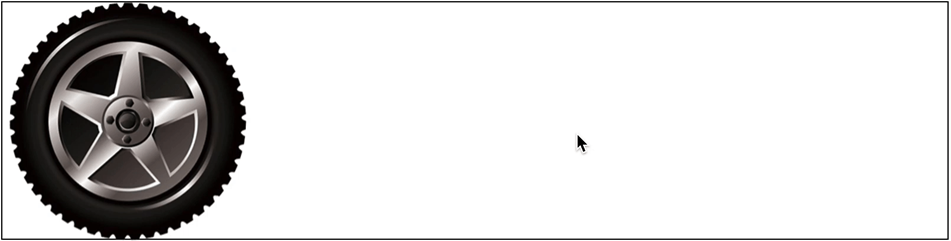

文件：`code/08-多重转换效果.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 800px;
  height: 200px;
  border: 1px solid #000;
}

img {
  width: 200px;
  transition: all 5s;
}

/* 鼠标移入box，图片边走边转 */
.box:hover img {
  /* 先平移再旋转 */
  transform: translate(600px) rotate(360deg);

  /* 旋转会改变坐标轴向 */
  /* 多重转换：以第一种转换形态的坐标轴为准 */
  /* transform: rotate(360deg) translate(600px); */

  /* 层叠性 */
  /* transform: translate(600px);
  transform: rotate(360deg); */
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <img src="./images/tyre1.png" alt="" />
</div>
```

盒子800px宽，轮胎200px宽，向右移动600px后恰好到达内容区右端；同时旋转360deg，5秒过渡展示“边走边转”。

不能把两个函数拆成两条同名声明：后写的 `transform: rotate(...)`会覆盖前面的平移。源码将这一错误对比和“旋转写在前面”的另一写法都注释起来，实际启用的是 `translate(600px) rotate(360deg)`。

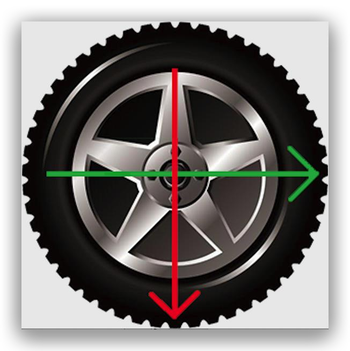

原课用“旋转改变坐标轴向”解释顺序差异：`rotate(...) translate(...)`会把平移方向一起旋转，轨迹可能偏离原先的水平轴。

补充：这里“先平移再旋转”指函数的书写顺序，不表示时间上先移动完再旋转；两个效果同时过渡。从点的几何变换看，函数列表组合按从右到左作用，因此 `translate(...) rotate(...)`保留外层的水平平移，而不是沿旋转后的方向移动。360deg的最终朝向相同，比较顺序要观察过渡途中。


### 1.9 缩放：以转换原点为中心改变视觉尺寸

```css
transform: scale(缩放倍数);
transform: scale(X轴缩放倍数, Y轴缩放倍数);
```

只写一个数，X、Y等比例缩放；常用正倍数中，大于1放大，0与1之间缩小，等于1不变。

文件：`code/09-缩放效果.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  width: 300px;
  height: 210px;
  margin: 100px auto;
  background-color: pink;
}

.box img {
  width: 100%;
  transition: all 0.5s;
}

.box:hover img {
  /* 修改宽高尺寸，从左上角开始缩放 */
  /* width: 500px;
  height: 400px; */

  /* 大于1，表示放大 */
  transform: scale(2);

  /* 小于1，表示缩小 */
  transform: scale(0.5);

  /* 等于1，不变 */
  transform: scale(1);
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <img src="./images/product.jpeg" alt="" />
</div>
```

图片默认宽度为父级的100%，设置0.5秒过渡。修改 `width`、`height`会改变布局尺寸，而 `scale`默认围绕中心改变视觉尺寸，布局占位仍保持原尺寸。

源码依次写了2、0.5、1，最终 `scale(1)`生效，所以直接悬停看不到放大或缩小。比较时让2或0.5单独生效即可。修改宽高的对比代码已经注释。

补充：原课“小于1缩小”的说法针对常用非负比例；0会压缩到零，负数还会翻转，不能将所有负数都理解为普通缩小。本日案例使用正倍数。


### 1.10 播放特效：大且透明变为小且可见

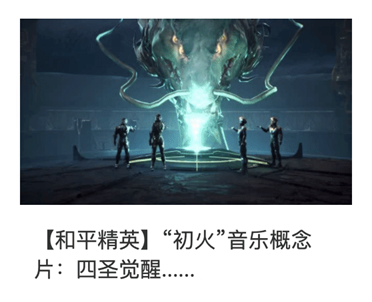

文件：`code/10-案例-按钮缩放/按钮缩放.html`。

CSS（放在 `<style>` 内）：

```css
* {
  margin: 0;
  padding: 0;
}

li {
  list-style: none;
}

img {
  width: 100%;
}

.box {
  width: 249px;
  height: 210px;
  margin: 50px auto;     
}

.box p {
  color: #3b3b3b;
  padding: 10px 10px 0 10px;
}

/* 1. 摆放播放按钮：图片区域的中间 */
.box li {
  overflow: hidden;
}

.pic {
  position: relative;
}

.pic::after {
  position: absolute;
  left: 50%;
  top: 50%;
  /* margin-left: -29px;
  margin-top: -29px; */
  /* transform: translate(-50%, -50%); */

  content: '';
  width: 58px;
  height: 58px;
  background-image: url(./images/play.png);
  transform: translate(-50%, -50%) scale(5);
  opacity: 0;

  transition: all .5s;
}
/* 2. hover效果：大按钮，看不见：透明是0 → 小按钮，看得见：透明度1 */
.box li:hover .pic::after {
  transform: translate(-50%, -50%) scale(1);
  opacity: 1;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <ul>
    <li>
      <div class="pic">
        <img src="./images/party.jpeg" alt="" />
      </div>
      <p>【和平精英】“初火”音乐概念片：四圣觉醒......</p>
    </li>
  </ul>
</div>
```

先用 `.pic`作为定位参照，在 `::after`里生成58×58px播放图标。`left: 50%; top: 50%`加上 `translate(-50%, -50%)`把它放到图片中央。

默认状态用 `scale(5)`把图标放大五倍，`opacity: 0`令它不可见；悬停列表项时变为 `scale(1)`与 `opacity: 1`，在0.5秒内缩回正常大小并显现。

两个状态都保留居中平移。若悬停时只写 `scale(1)`，会覆盖原来的平移，按钮左上角就落在图片中心，失去居中效果。

列表项的 `overflow: hidden`裁切放大图标越界的部分。图片设置100%宽度，但该例没有专门清除图片基线下间隙；这里保留源码，不把图片容器高度假设成精确等于图片像素高度。

查看时鼠标移入卡片，播放图标从大且透明变为正常大小且可见，移开后反向过渡。伪元素只是视觉图标，当前没有播放行为。


### 1.11 倾斜：skew的角度单位也是deg

原课用 `transform: skew(...)`给盒子添加倾斜效果。

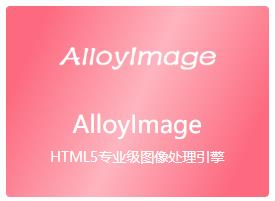

文件：`code/11-倾斜效果.html`。

CSS（放在 `<style>` 内）：

```css
div {
  margin: 100px auto;
  width: 100px;
  height: 200px;
  background-color: pink;
  transition: all 0.5s;
}

div:hover {
  transform: skew(30deg);
  transform: skew(-30deg);
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

只写一个角度主要表示沿X方向的错切：盒子不同高度的部分产生不同水平偏移，外观像平行四边形。它与把整个盒子转一个角度的 `rotate`不同。

源码后写的 `skew(-30deg)`覆盖30deg。悬停时观察粉色盒子在0.5秒内倾斜，离开后恢复；图片示例用于说明效果，不是本文件的粉色盒子截图。


## 2. 渐变

渐变是多个颜色逐渐变化的效果，常用于盒子背景。这里使用 `background-image`设置渐变图像，而不是把渐变写进 `background-color`。

| 类型 | 变化方向 | 常见用途 |
| --- | --- | --- |
| 线性渐变 | 沿直线方向变化 | 上下遮罩、左右按钮色彩 |
| 径向渐变 | 从中心向周围变化 | 圆形色彩、局部高光 |

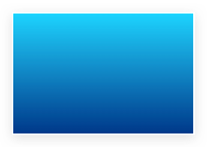

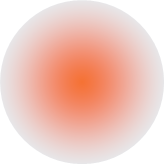

渐变可以包含透明颜色。半透明渐变覆盖在背景色或图片上时，会与下面的内容叠合，这是本日遮罩和按钮高光的基础。


### 2.1 线性渐变：方向与颜色位置

原课语法结构：

```css
background-image: linear-gradient(
  渐变方向,
  颜色1 终点位置,
  颜色2 终点位置,
  ...
);
```

这段含中文占位词，是语法说明。方向与颜色位置都可省略；方向可以是 `to`加方位名词，也可以是角度，颜色位置可以用百分比。

文件：`code/12-渐变-线性.html`。

CSS（放在 `<style>` 内）：

```css
div {
  width: 200px;
  height: 200px;
  background-color: green;
  background-image: linear-gradient(
    red,
    green
  );
  background-image: linear-gradient(
    to right,
    red,
    green
  );
  background-image: linear-gradient(
    45deg,
    red,
    green
  );
  background-image: linear-gradient(
    red 80%,
    green
  );
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
```

四种写法依次比较：默认从上往下；`to right`从左往右；45deg从左下向右上；`red 80%, green`表示红色停点在80%，后段逐渐过渡到绿色。

补充：课件把颜色位置称为“终点位置”，更准确地说是颜色停点。该位置确定这个颜色在渐变中的位置；只有写不同颜色的停点才形成相应过渡。

源码最后一条渐变生效，当前应看到前80%基本为红色，到底部才向绿色变化。前面的方向例子不会同时叠加；`background-color: green`保留在渐变背景下面。


### 2.2 产品展示：透明到半透明黑色的遮罩

原课希望图片上方尽量保留原色，下方压暗，突出白色标题。

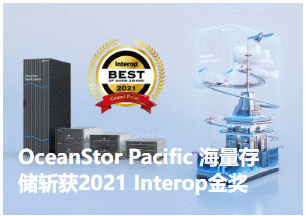

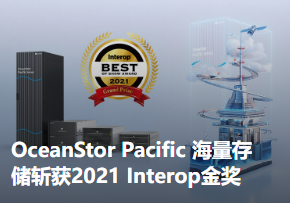

文件：`code/13-案例-产品展示.html`。

CSS（放在 `<style>` 内）：

```css
.box {
  position: relative;
  width: 300px;
  height: 212px;
}

.box img {
  width: 300px;
}

.box .title {
  position: absolute;
  left: 15px;
  bottom: 20px;
  z-index: 2;
  width: 260px;
  color: #fff;
  font-size: 20px;
  font-weight: 700;
}

.mask {
  position: absolute;
  left: 0;
  top: 0;
  width: 100%;
  height: 100%;
  background-image: linear-gradient(
      transparent,
      rgba(0,0,0,0.5)
  );
  opacity: 0;

  transition: all .5s;
}

.box:hover .mask {
  opacity: 1;
}
```

HTML（放在 `<body>` 内）：

```html
<div class="box">
  <img src="./images/product.jpeg" alt="" />
  <div class="title">OceanStor Pacific 海量存储斩获2021 Interop金奖</div>
  <div class="mask"></div>
</div>
```

父盒子300×212px，相对定位。图片作为底层，标题绝对定位到左侧15px、底部20px，`z-index: 2`让它位于遮罩上方。

`.mask`铺满整个父盒子，背景默认向下从 `transparent`渐变到 `rgba(0,0,0,0.5)`。默认透明度0，悬停父盒子时变1，在0.5秒内让整层遮罩显现。

需要区分两种透明：渐变中的透明颜色控制遮罩内部不同位置的暗度；`opacity`控制整层是否显示。标题不在 `.mask`内部，所以遮罩的透明度变化不会让标题同步隐藏。

补充：PPT示例写底部黑色透明度0.6，配套Markdown与HTML采用0.5，本篇代码以HTML为准。原图只是效果参考，文字换行和显示比例以当前300px盒子为准。

查看时标题始终存在，悬停后图片下方逐渐变暗，标题仍在上面。


### 2.3 径向渐变：半径、圆心与按钮高光

原课语法结构：

```css
background-image: radial-gradient(
  半径 at 圆心位置,
  颜色1 终点位置,
  颜色2 终点位置,
  ...
);
```

一个半径可得到圆形渐变，两个长度表示椭圆的水平、垂直半径。圆心位置可用像素、百分比或方位名词。

文件：`code/14-渐变-径向.html`。

CSS（放在 `<style>` 内）：

```css
div {
  width: 100px;
  height: 100px;
  background-color: pink; 
  border-radius: 50%;
  background-image: radial-gradient(
    50px at center center,
    red,
    pink
  );
  background-image: radial-gradient(
    50px 20px at center center,
    red,
    pink
  );
  background-image: radial-gradient(
    50px at 50px 30px,
    red,
    pink 50%
  );
}

button {
  width: 100px;
  height: 40px;
  background-color: green;
  border: 0;
  border-radius: 5px;
  color: #fff;
  background-image: radial-gradient(
    30px at 30px 20px,
    rgba(255, 255, 255, 0.2),
    transparent
  );
}
```

HTML（放在 `<body>` 内）：

```html
<div></div>
<button>按钮</button>
```

圆形盒子的三条背景声明依次示范：中心处半径50px的圆；50×20px的椭圆；圆心在 `(50px, 30px)`、半径50px，并把粉色停点放在50%。最后一条生效，因此红色中心略偏上，较早过渡成粉色。

按钮先设置绿色底色，再叠半径30px、圆心 `(30px, 20px)`的渐变，从半透明白色到透明，形成局部亮点。透明区域让绿色底色露出来。

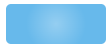

圆角只控制外形裁切，与径向渐变的半径是两件事。查看时圆形色块与带高光的按钮同时出现。


## 3. 综合案例：喜马拉雅

综合案例把转换与渐变嵌入一份现成页面：导航箭头旋转、频道弹层平移、搜索和登录按钮渐变、三张横幅的缩放排布、专辑遮罩和播放图标、客户端按钮高光。

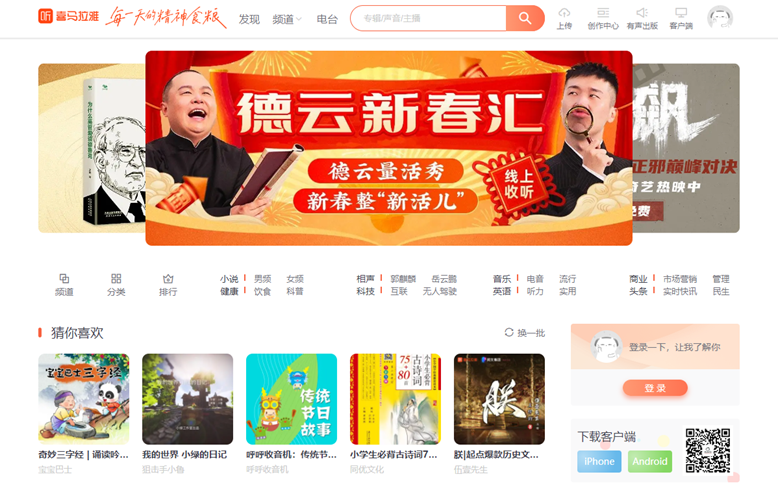

项目目录：`code/15-综合案例-喜马拉雅/`。HTML引入 `css/font.css`与 `css/index.css`，图片放在 `assets`中。配套笔记按“导航频道 → 渐变按钮 → 轮播图 → 猜你喜欢”展开；下面沿用这个讲解顺序，并注明课堂CSS里的TODO编号。

补充：TODO1～8旁边已经有实现代码，`TODO`只是课堂标记，不表示这些效果尚未完成。本项目是1080px固定版心的静态案例，没有自动轮播、播放、登录或“换一批”的业务脚本。


### 3.1 页面结构与基础布局

`index.html`原文：

```html
<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>喜马拉雅</title>
    <link rel="stylesheet" href="./css/font.css">
    <link rel="stylesheet" href="./css/index.css" />
  </head>
  <body>
    <header class="x-header">
      <div class="container">
        <a href="#" class="x-header-logo">喜马拉雅</a>
        <nav class="x-header-nav">
          <a href="#" class="nav-item">发现</a>
          <a href="#" class="nav-item">
            频道<span class="iconfont icon-down"></span>
            <div class="channel-layer">
              所有频道<br>
              所有频道<br>
              所有频道<br>
              所有频道<br>
            </div>
          </a>
          <a href="#" class="nav-item">电台</a>
        </nav>
        <div class="x-header-search">
          <form action="#">
            <input type="text" placeholder="专辑/声音/主播" />
            <a href="#" class="btn">
              <span class="iconfont icon-search"></span>
            </a>
          </form>
        </div>
        <div class="x-header-icons">
          <a href="#" class="icons-item">
            <span class="iconfont icon-cloud-upload"></span>
            <span class="tit">上传</span>
          </a>
          <a href="#" class="icons-item">
            <span class="iconfont icon-pic-left"></span>
            <span class="tit">创作中心</span>
          </a>
          <a href="#" class="icons-item">
            <span class="iconfont icon-sound"></span>
            <span class="tit">有声出版</span>
          </a>
          <a href="#" class="icons-item">
            <span class="iconfont icon-desktop"></span>
            <span class="tit">客户端</span>
          </a>
          <a href="#" class="icons-item">
            <img src="./assets/avatar.png" alt="" />
          </a>
        </div>
      </div>
    </header>
    <main class="x-main">
      <div class="container">
        <!-- banner -->
        <div class="banner">
          <ul class="banner-list">
            <li class="banner-item left">
              <a href="#">
                <img src="./assets/banner01.jpg" alt="" />
              </a>
            </li>
            <li class="banner-item">
              <a href="#">
                <img src="./assets/banner02.jpg" alt="" />
              </a>
            </li>
            <li class="banner-item right">
              <a href="#">
                <img src="./assets/banner03.jpg" alt="" />
              </a>
            </li>
          </ul>
        </div>
        <!-- category -->
        <nav class="category">
          <div class="category-top">
            <a href="#" class="top-item">
              <span class="iconfont icon-block top-item-icon"></span>
              <span>频道</span>
            </a>
            <a href="#" class="top-item">
              <span class="iconfont icon-appstore top-item-icon"></span>
              <span>分类</span>
            </a>
            <a href="#" class="top-item">
              <span class="iconfont icon-crown top-item-icon"></span>
              <span>排行</span>
            </a>
          </div>
          <div class="category-sub">
            <div class="category-sub-item">
              <a href="#" class="start">小说</a>
              <a href="#">男频</a>
              <a href="#">女频</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">相声</a>
              <a href="#">郭麒麟</a>
              <a href="#">岳云鹏</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">音乐</a>
              <a href="#">电音</a>
              <a href="#">流行</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">商业</a>
              <a href="#">市场营销</a>
              <a href="#">管理</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">健康</a>
              <a href="#">饮食</a>
              <a href="#">科普</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">科技</a>
              <a href="#">互联</a>
              <a href="#">无人驾驶</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">英语</a>
              <a href="#">听力</a>
              <a href="#">实用</a>
            </div>
            <div class="category-sub-item">
              <a href="#" class="start">头条</a>
              <a href="#">实时快讯</a>
              <a href="#">民生</a>
            </div>
          </div>
        </nav>
        <!-- layout -->
        <section class="layout">
          <!-- 主体内容  -->
          <div class="layout-main">
            <div class="panel">
              <div class="panel-head">
                <h3 class="panel-head-tit">猜你喜欢</h3>
                <a class="panel-head-toggle" href="#">
                  <span class="iconfont icon-sync"></span>
                  <span>换一批</span>
                </a>
              </div>
              <div class="panel-body">
                <ul>
                  <li>
                    <a href="#" class="album-item">
                      <div class="album-item-box">
                        <img class="img" src="./assets/img01.jpg" alt="" />
                      </div>
                      <p class="album-item-tit">奇妙三字经 | 诵读吟唱经典磨耳朵 | 宝宝巴士国学</p>
                      <p class="album-item-aut">宝宝巴士</p>
                    </a>
                  </li>
                  <li>
                    <a href="#" class="album-item">
                      <div class="album-item-box">
                        <img class="img" src="./assets/img02.jpg" alt="" />
                      </div>
                      <p class="album-item-tit">我的世界 小绿的日记</p>
                      <p class="album-item-aut">狙击手小鲁</p>
                    </a>
                  </li>
                  <li>
                    <a href="#" class="album-item">
                      <div class="album-item-box">
                        <img class="img" src="./assets/img03.jpg" alt="" />
                      </div>
                      <p class="album-item-tit">呼呼收音机：传统节日故事</p>
                      <p class="album-item-aut">呼呼收音机</p>
                    </a>
                  </li>
                  <li>
                    <a href="#" class="album-item">
                      <div class="album-item-box">
                        <img class="img" src="./assets/img04.jpg" alt="" />
                      </div>
                      <p class="album-item-tit">小学生必背古诗词75+80首</p>
                      <p class="album-item-aut">同优文化</p>
                    </a>
                  </li>
                  <li>
                    <a href="#" class="album-item">
                      <div class="album-item-box">
                        <img class="img" src="./assets/img05.jpg" alt="" />
                      </div>
                      <p class="album-item-tit">朕|起点爆款历史文｜架空权谋&逆袭成帝|VIP免费有声小说</p>
                      <p class="album-item-aut">伍壹先生</p>
                    </a>
                  </li>
                </ul>
              </div>
            </div>
          </div>
          <!-- 侧边栏 -->
          <div class="layout-aside">
            <div class="card">
              <div class="card-head">
                <img class="avatar" src="./assets/avatar.png" alt="" />
                <p class="text">登录一下，让我了解你</p>
              </div>
              <div class="card-info">
                <a href="#" class="login">登 录</a>
              </div>
            </div>
            <div class="download">
              <div class="dl">
                <p class="dl-tit">下载客户端</p>
                <a href="#" class="dl-btn">iPhone</a>
                <a href="#" class="dl-btn">Android</a>
              </div>
              <img src="./assets/hm.jpg" alt="">
            </div>
          </div>
        </section>
      </div>
    </main>
  </body>
</html>
```

先按层级识别效果作用的元素：头部包含logo、导航、搜索和图标入口；主区域包含横幅、分类、猜你喜欢；右侧是登录卡片和客户端下载。

`css/index.css`开头原文，包含重置、版心、头部与导航基础样式：

```css
*,
::after,
::before {
  box-sizing: border-box;
}

body {
  margin: 0;
  font-family:
    -apple-system,
    BlinkMacSystemFont,
    PingFangSC-Regular,
    "PingFang SC",
    "Microsoft YaHei",
    "Helvetica Neue",
    Helvetica,
    Arial,
    sans-serif;
  font-size: 14px;
  color: #40404c;
}

a {
  color: #40404c;
  text-decoration: none;
}

a:hover {
  color: #fc5832;
}

ul {
  list-style: none;
}

h1,
h2,
h3,
h4,
h5,
h6,
ul,
ol,
p {
  padding: 0;
  margin: 0;
}

.container {
  width: 1080px;
  margin: 0 auto;
}

/* 头部 */
.x-header {
  position: relative;
  z-index: 9;
  height: 60px;
}

.x-header::after {
  position: absolute;
  bottom: 0;
  left: 0;
  z-index: -1;
  width: 100%;
  height: 60px;
  content: "";
  box-shadow: 0 2px 2px 0 rgb(0 0 0 / 10%);
}

.x-header .container {
  display: flex;
  align-items: center;
  background-color: #fff;
}

.x-header-logo {
  position: relative;
  z-index: 9;
  width: 290px;
  height: 60px;
  font-size: 0;
}

.x-header-logo::before {
  position: absolute;
  top: 0;
  right: 0;
  bottom: 0;
  left: 0;
  background: url("../assets/logo.png") no-repeat center / contain;
  content: "";
}

.x-header-nav {
  display: flex;
  width: 180px;
  margin: 5px;
}

.x-header-nav .nav-item {
  flex: 1;
  font-size: 16px;
  color: #72727b;
  text-align: center;
}

.x-header-nav .nav-item:hover {
  color: #40404c;
}
```

版心1080px，头部60px高；头部内部已有Flex排布与垂直居中。`.x-header`相对定位并设层级9，为下方频道弹层提供定位和层级环境，logo用伪元素背景呈现。

本日主要是在现成结构里补动态视觉效果，不重新设计整个页面。后面的转换只选中相应图标、弹层或图片，不对整个区域一起转换。


### 3.2 导航频道：箭头旋转，列表从上方滑出

`css/index.css`中的TODO1、TODO2及频道弹层原文：

```css
/* TODO 1. 箭头旋转 */
.x-header-nav .nav-item .icon-down {
  display: inline-block;
  height: 16px;
  color: #ccc;
  transition: all 0.5s;
}

.x-header-nav .nav-item:hover .icon-down {
  transform: rotate(-180deg);
}

.channel-layer {
  position: absolute;
  top: 60px;
  left: 50%;
  z-index: -2;
  width: 1080px;
  height: 120px;
  padding: 10px;
  margin-left: -540px;
  color: #72727b;
  background-color: #f5f5f5;
  border: 1px solid #e4e4e4;
  border-top: none;
  transition: all 0.5s;
  transform: translateY(-120px);
}

/* TODO 2. 弹窗频道 */
.x-header-nav .nav-item:hover .channel-layer {
  transform: translateY(0);
}
```

箭头 `span.icon-down`先转为行内块，使它可以应用转换；默认设置0.5秒过渡。鼠标移入该 `.nav-item`，箭头逆时针旋转180deg，呈现展开状态。

频道层绝对定位在 `top: 60px`，宽1080px、高120px；`left: 50%`配合 `margin-left: -540px`在头部参照区域内水平居中。

默认向上移动120px，悬停时变为 `translateY(0)`，列表在0.5秒内回到头部下方。头部内的白色背景与负层级配合遮住收起状态；这里不是把元素设置成 `display: none`。

`.channel-layer`位于包含“频道”的链接内部，所以仍在该项的悬停范围中。当前内容是四行重复“所有频道”，没有完整频道菜单。

补充：弹层没有自己的定位祖先 `.nav-item`规则，因此绝对定位参照已有相对定位的 `.x-header`。`z-index: -2`在头部的层叠环境中使用，不能简单理解为它一定位于整个网页最底层。

查看时悬停“频道”，箭头翻转，弹层向下滑出；移开后收起。


### 3.3 渐变按钮之一：搜索按钮从浅色过渡到主题色

`css/index.css`搜索区原文，包含TODO3：

```css
.x-header-search {
  width: 300px;
}

.x-header-search form {
  position: relative;
  width: 100%;
}

.x-header-search form input {
  width: 100%;
  height: 40px;
  padding: 0 20px;
  border: 1px solid #f86442;
  border-radius: 20px;
  outline: none;
}

.x-header-search form input::placeholder {
  color: #ccc;
}

/* TODO 3. 渐变按钮 */
.x-header-search form .btn {
  position: absolute;
  top: 0;
  right: 0;
  width: 60px;
  height: 40px;
  line-height: 40px;
  text-align: center;
  background-color: #f86442;
  border-top-right-radius: 20px;
  border-bottom-right-radius: 20px;
  background-image: linear-gradient(
    to right,
    rgba(255, 255, 255, 0.3),
    #f86442
  );
}

.x-header-search form .btn span {
  font-size: 24px;
  color: #fff;
}
```

搜索区域宽300px，表单相对定位。输入框高40px、圆角20px；60×40px的搜索入口绝对定位到表单右上角，右侧上下圆角20px，与输入框右端形成一体。

按钮先设置 `#f86442`底色，再叠从左向右的线性渐变：左端半透明白色使底色变亮，右端回到不透明主题色。

搜索符号使用字体图标，大小24px、白色。查看时按钮左侧略浅、右侧较深，而不是整块单色。

补充：按钮在HTML中是指向 `#`的 `a`，不是提交按钮，当前没有搜索实现。输入框左右20px内边距没有专门为60px按钮增加右侧避让，输入很长时要留意文字是否被覆盖；以上保留课堂源码。


### 3.4 渐变按钮之二：登录按钮

`css/index.css`登录卡片原文，包含TODO7：

```css
.card {
  margin-bottom: 20px;
  overflow: hidden;
  background-color: #f9f9fa;
  border-radius: 4px;
}

.card .card-head {
  display: flex;
  height: 70px;
  background: url("../assets/bg01.png") no-repeat center / cover;
  align-items: center;
  justify-content: center;
}

.card .card-head .avatar {
  width: 50px;
  height: 50px;
  vertical-align: bottom;
  border-radius: 50%;
}

.card .card-head .text {
  margin-left: 10px;
  color: #72727b;
}

.card .card-info {
  display: flex;
  height: 56px;
  align-items: center;
  justify-content: center;
}

/* TODO 7. 渐变按钮 */
.card .card-info .login {
  padding: 3px 34px;
  color: #fff;
  background-color: #ff7251;
  border-radius: 30px;
  box-shadow: 0 4px 8px 0 rgb(252 88 50 / 50%);
  background-image: linear-gradient(
    to right,
    rgba(255, 255, 255, 0.2),
    #ff7251
  );
}
```

卡片顶部采用Flex，让50px圆形头像与提示文字居中。下面56px高的 `.card-info`居中放登录链接。

登录按钮使用 `#ff7251`背景、30px圆角和橙色阴影，线性渐变从半透明白色过渡到主题色。阴影让按钮与浅色卡片背景有层次，渐变改变按钮表面明暗。

半透明白色的alpha为0.2，与搜索按钮的0.3不同，不能把两种按钮的渐变参数混为同一条规则。这里没有悬停渐变切换，渐变在默认状态就显示。

查看时登录按钮有圆润外形、左侧浅色与下方阴影；点击仍是占位链接。


### 3.5 渐变按钮之三：客户端下载的径向高光

`css/index.css`下载区域原文，包含TODO8：

```css
.download {
  display: flex;
  padding: 10px;
  overflow: hidden;
  background-color: pink;
  background: #f9f9fa url("../assets/bg02.png") no-repeat 4px 25px / 100%;
  border-radius: 4px;
  justify-content: space-between;
  align-items: center;
}

.download .dl {
  display: flex;
  flex-wrap: wrap;
}

.download .dl .dl-tit {
  width: 100%;
  margin-bottom: 10px;
  font-size: 18px;
}

/* TODO 8. 径向渐变 */
.download .dl .dl-btn {
  width: 68px;
  height: 34px;
  line-height: 34px;
  color: #fff;
  text-align: center;
  border-radius: 4px;
  background-image: radial-gradient(
    50px at 10px 10px,
    rgba(255, 255, 255, 0.5),
    transparent
  );
}

.download .dl .dl-btn:nth-of-type(1) {
  background-color: #67b9eb;
}

.download .dl .dl-btn:nth-of-type(2) {
  margin-left: 10px;
  background-color: #86d864;
}
```

下载区已有背景图和右侧二维码，内部Flex布局允许按钮换行。两个按钮各68×34px，第一项蓝色，第二项绿色并增加10px左间距。

两个按钮共用径向渐变：半径50px，圆心位于按钮左上方附近的 `(10px, 10px)`，颜色从alpha0.5的白色到透明，形成左上角高光。按钮各自的底色透过渐变显示。

`nth-of-type(1)`和 `nth-of-type(2)`在这里按 `a`标签的同类型顺序选中两个链接，不把前面的标题 `p`计作第一个按钮。

补充：`.download`先写 `background-color: pink`，后写完整 `background: #f9f9fa ...`，后者覆盖了粉色底色；实际底色是 `#f9f9fa`。背景图片缩放和按钮高光是不同层的规则。

查看时两个按钮保留各自底色，并在左上方显得更亮，没有真实下载动作。


### 3.6 三张横幅：中间大，两侧小

`css/index.css`主区域与横幅原文，包含TODO4：

```css
.x-main {
  padding-top: 20px;
}

.banner {
  position: relative;
  width: 100%;
  height: 300px;
  margin-bottom: 20px;
}

.banner .banner-list {
  position: relative;
  z-index: 8;
  width: 100%;
  height: 100%;
}

.banner .banner-list .banner-item {
  position: absolute;
  top: 0;
  left: 165px;
  z-index: 1;
  width: 750px;
  height: 300px;
  overflow: hidden;
  border-radius: 10px;
  transition: all 0.5s;
}

/* TODO 4. 摆放图片 */
.banner .banner-list .banner-item.left {
  z-index: 0;
  transform: translate(-160px) scale(0.8);
  transform-origin: left center;
}

.banner .banner-list .banner-item.right {
  z-index: 0;
  transform: translate(160px) scale(0.8);
  transform-origin: right center;
}

.banner .banner-list .banner-item a img {
  width: 100%;
  height: 100%;
  vertical-align: bottom;
}
```

横幅区域1080×300px。三张 `.banner-item`都绝对定位到 `left: 165px; top: 0`，本身750×300px；因为 `(1080 - 750) / 2 = 165`，默认位置正好居中。

中间图片保留层级1，两侧层级0。左边向左平移160px并缩放到0.8，原点设为左边中点；右边向右平移160px并缩放到0.8，原点设为右边中点。这样中间完整大图覆盖在两张小图前面，露出左右侧图。

原点不同决定缩放时向哪一边收缩，不能只写同样的 `scale(0.8)`就认为会得到相同侧边位置。每张图的 `overflow: hidden`与10px圆角用于裁切自身图片。

补充：三张图片的左右类名已经写在HTML里，源码没有更换类名的脚本。因此这一步实现的是轮播图的静态排布，`transition`虽已设置，但不会自行触发周期切换。

查看时中间横幅大且在前，两侧横幅小且在后。


### 3.7 猜你喜欢：遮罩显现、播放图标变大、封面放大

`css/index.css`专辑区域原文，包含TODO5、TODO6：

```css
.album-item {
  width: 100%;
}

.album-item .album-item-box {
  position: relative;
  width: 100%;
  overflow: hidden;
  border-radius: 10px;
}

.album-item .album-item-box .img {
  width: 100%;
  vertical-align: bottom;
  transition: all 0.5s;
}

.album-item .album-item-tit {
  padding: 5px 0;
  overflow: hidden;
  font-weight: 700;
  text-overflow: ellipsis;
  white-space: nowrap;
}

.album-item .album-item-aut {
  font-size: 13px;
  color: #ccc;
}


/* TODO 5. 播放按钮和遮罩 */
.album-item .album-item-box::after {
  position: absolute;
  left: 0;
  top: 0;
  content: '';
  width: 100%;
  height: 100%;
  background: rgba(0,0,0,.5) url(../assets/play.png) no-repeat center / 20px;
  opacity: 0;
  transition: all .5s;
}

.album-item .album-item-box:hover::after {
  opacity: 1;
  background-size: 50px;
}


/* TODO 6. 图片缩放 */
.album-item .album-item-box:hover img {
  transform: scale(1.1);
}
```

专辑图片容器相对定位、圆角10px并裁切溢出。图片默认宽100%，0.5秒过渡；标题单行显示，超出宽度时用省略号，作者文字13px、浅灰色。

这里的 `::after`与前面独立播放案例不同：它铺满图片容器，背景同时包含半透明黑色和居中的播放图标，默认图标尺寸20px，整层透明度0。

鼠标移入 `.album-item-box`后，伪元素透明度变1，图标的 `background-size`变成50px；与此同时，图片 `scale(1.1)`放大到1.1倍，超出的部分由容器裁切。

因此同一次悬停包含三个变化：遮罩显现、图标由小变大、图片轻微放大。独立播放案例是58px伪元素从 `scale(5)`缩小到1，不能把两套实现混为一套参数。

查看时悬停某张封面，它变暗并显示较大的播放图标，图片有轻微放大；离开后恢复。页面没有音频播放逻辑，“换一批”也仍是占位入口。


### 3.8 其余基础样式与字体图标文件

本日效果依赖项目已有的头部图标、分类和主体列布局。下面是 `css/index.css`中尚未在前面出现的连续原文片段；与前面各片段合在一起覆盖整份CSS。

头部图标入口：

```css
.x-header-icons {
  display: flex;
  width: 300px;
  align-items: center;
}

.x-header-icons .icons-item {
  flex: 1;
  text-align: center;
}

.x-header-icons .icons-item .iconfont {
  font-size: 20px;
  color: #ccc;
}

.x-header-icons .icons-item:hover .iconfont {
  color: #f86442;
}

.x-header-icons .icons-item .tit {
  display: block;
  font-size: 12px;
  color: #72727b;
}

.x-header-icons .icons-item img {
  width: 40px;
  height: 40px;
  vertical-align: bottom;
  border-radius: 20px;
}
```

分类区、主列与侧栏、专辑面板基础布局：

```css
.category {
  display: flex;
  width: 100%;
  padding: 20px 0;
  align-items: center;
}

.category-top {
  display: flex;
  width: 240px;
}

.category-top .top-item {
  color: #72727b;
  text-align: center;
  flex: 1;
}

.category-top .top-item:hover {
  color: #f86442;
}

.category-top .top-item .top-item-icon {
  display: block;
  font-size: 20px;
}

.category-sub {
  display: flex;
  width: 840px;
  flex-wrap: wrap;
}

.category-sub-item {
  width: 210px;
  padding-left: 30px;
}

.category-sub-item a {
  padding: 0 10px;
  font-size: 13px;
  color: #72727b;
}

.category-sub-item a.start {
  position: relative;
  font-size: 14px;
  color: #40404c;
}

.category-sub-item a.start::after {
  position: absolute;
  top: 3px;
  right: -1px;
  width: 2px;
  height: 10px;
  background-color: #f86442;
  content: "";
}

.layout {
  display: flex;
  width: 100%;
  padding-top: 20px;
}

.layout-main {
  width: 780px;
}

.layout-aside {
  width: 260px;
  margin-left: 40px;
}

.panel {
  margin-bottom: 20px;
}

.panel-head {
  display: flex;
  margin-bottom: 20px;
  justify-content: space-between;
}

.panel-head .panel-head-tit {
  position: relative;
  padding-left: 20px;
  font-size: 20px;
  font-weight: normal;
}

.panel-head .panel-head-tit::before {
  position: absolute;
  top: 6px;
  left: 0;
  width: 5px;
  height: 15px;
  background-color: #f86442;
  border-radius: 6px;
  content: "";
}

.panel-head .panel-head-toggle {
  display: flex;
  align-items: center;
  color: #72727b;
}

.panel-head .panel-head-toggle .icon-sync {
  margin-right: 5px;
}

.panel-body ul {
  display: flex;
  justify-content: space-between;
}

.panel-body ul li {
  width: 140px;
}
```

这些规则负责把分类与卡片排好，主要使用Flex。主列780px、侧栏260px加40px间距，总宽1080px；专辑列表每项140px，使用 `space-between`分配剩余间隔。本日转换效果不改变这组布局占位。

字体图标定义文件 `css/font.css`原文：

```css
@font-face {
  font-family: "iconfont"; /* Project id 3868932 */
  src: url('./font_3868932_yoa65s6xn5.woff2') format('woff2'),
       url('./font_3868932_yoa65s6xn5.woff') format('woff'),
       url('./font_3868932_yoa65s6xn5.ttf.ttf?t=1674978058821') format('truetype');
}

.iconfont {
  font-family: "iconfont" !important;
  font-size: 16px;
  font-style: normal;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

.icon-up:before {
  content: "\e658";
}

.icon-left:before {
  content: "\e659";
}

.icon-down:before {
  content: "\e65a";
}

.icon-right:before {
  content: "\e65b";
}

.icon-search:before {
  content: "\e8ef";
}

.icon-sync:before {
  content: "\e786";
}

.icon-edit-square:before {
  content: "\e791";
}

.icon-appstore:before {
  content: "\e792";
}

.icon-cloud-upload:before {
  content: "\e7d9";
}

.icon-sound:before {
  content: "\e7da";
}

.icon-block:before {
  content: "\e7df";
}

.icon-pic-left:before {
  content: "\e7f6";
}

.icon-crown:before {
  content: "\e842";
}

.icon-desktop:before {
  content: "\e843";
}
```

它通过 `@font-face`加载字体，公共 `.iconfont`指定字体，再由 `.icon-down`、`.icon-search`等伪元素显示对应编码。

补充：该文件第三个字体URL写成 `font_3868932_yoa65s6xn5.ttf.ttf?t=...`，本包实际文件为单个 `.ttf`，该备用路径有拼写错误。前面的 `.woff2`与 `.woff`文件存在，支持它们的浏览器仍可使用；这里保留原文并标明问题。课堂页面引用的HTML、CSS、图片与前两种字体路径均已核对。


## 4. 配套作业：华为产品展示

作业把图片缩放、文字平移和渐变遮罩组合到三张新闻卡片。项目位于 `作业/华为产品/`，HTML用 `demo.html`，样式用 `css/demo.css`，图标样式用 `iconfont/iconfont.css`。


### 4.1 三张卡片的结构

`demo.html`原文：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>华为新闻</title>
    <link rel="stylesheet" href="./iconfont/iconfont.css">
    <link rel="stylesheet" href="./css/demo.css">
</head>

<body>
    <div class="box">
        <ul>
            <li>
                <a href="#">
                    <div class="pic">
                        <img src="./images/product.jpeg" alt="">
                    </div>
                    <div class="txt">
                        <h4>产品</h4>
                        <h5>OceanStor Pacific 海量存储斩获2021 Interop金奖</h5>
                        <p>
                            <span>了解更多</span>
                            <i class="iconfont icon-arrow-right"></i>
                        </p>
                    </div>
                </a>
            </li>
            <li>
                <a href="#">
                    <div class="pic">
                        <img src="./images/huawei1.jpeg" alt="">
                    </div>
                    <div class="txt">
                        <h4>行业洞察</h4>
                        <h5>迈向智能世界2030</h5>
                        <p>
                            <span>了解更多</span>
                            <i class="iconfont icon-arrow-right"></i>
                        </p>
                    </div>
                </a>
            </li>
            <li>
                <a href="#">
                    <div class="pic">
                        <img src="./images/huawei2.jpeg" alt="">
                    </div>
                    <div class="txt">
                        <h4>《ICT新视界》刊首语</h4>
                        <h5>笃行致远，共建具有获得感、幸福感、安全感的智慧城市</h5>
                        <p>
                            <span>了解更多</span>
                            <i class="iconfont icon-arrow-right"></i>
                        </p>
                    </div>
                </a>
            </li>
        </ul>
    </div>
</body>

</html>
```

每个 `li`包住一张图片和一块 `.txt`文字；文字包含类型、标题、“了解更多”与右箭头图标。三张分别使用产品、行业洞察、刊首语内容。


### 4.2 默认布局与悬停效果

`css/demo.css`原文：

```css
* {
    margin: 0;
    padding: 0;
    box-sizing: border-box;
}

li {
    list-style: none;
}

a {
    text-decoration: none;
}

img {
    width: 100%;
    vertical-align: middle;
}

.box {
    width: 1110px;
    height: 247px;
    margin: 20px auto;
    /* background-color: pink; */
}

.box li {
    position: relative;
    float: left;
    width: 350px;
    height: 247px;
    margin-right: 30px;
    overflow: hidden;
}

.box li:last-child {
    margin-right: 0;
}

.box .txt {
    position: absolute;
    left: 0;
    bottom: -50px;
    width: 350px;
    height: auto;
    padding: 20px 30px;
    z-index: 1;
    color: #fff;
    transition: transform .5s;
}

.box .txt h4 {
    font-size: 14px;
    font-weight: 400;
    line-height: 2em;
    color: #fff;
}

.box .txt h5 {
    margin-bottom: 40px;
    font-size: 18px;
    line-height: 1.5em;
    color: #fff;
}

.box .txt p {
    color: #fff;
    font-size: 14px;
}

.box .txt p .iconfont {
    color: #c7000b;
    vertical-align: middle;
    font-size: 20px;
    font-weight: 700;
}


/* 遮罩层 */

.box li a:after {
    position: absolute;
    left: 0;
    top: 0;
    z-index: 0;
    display: none;
    content: '';
    width: 100%;
    height: 100%;
    background-image: linear-gradient( transparent, rgba(0, 0, 0, .5));
}


/* hover效果 */

.box img {
    transition: all 0.5s;
}

.box li:hover a::after {
    display: block;
}

.box li:hover img {
    transform: scale(1.1);
}

.box li:hover .txt {
    transform: translateY(-50px);
}
```

三张卡片各350px宽，两段30px间距，总宽 `350 × 3 + 30 × 2 = 1110px`。最后一张去掉右间距，卡片高247px，相对定位并裁切溢出。

文字区绝对定位在 `bottom: -50px`，默认有一部分位于卡片下方；悬停后用 `translateY(-50px)`向上移动，露出“了解更多”。文字层级1，渐变遮罩层级0，使白字位于遮罩上方。

图片默认设置0.5秒过渡，悬停放大到1.1倍。遮罩从透明渐变到alpha0.5黑色，默认 `display: none`，悬停改为 `display: block`。

补充：这里遮罩通过 `display`直接切换，代码没有为遮罩设置 `opacity`过渡，所以它会立即出现；有0.5秒过渡的是图片缩放和文字平移。不要沿用课堂产品示例的“遮罩缓慢显现”描述。


### 4.3 右箭头字体图标

`iconfont/iconfont.css`原文：

```css
@font-face {
  font-family: "iconfont"; /* Project id 2577419 */
  src: url('iconfont.woff2?t=1622184279478') format('woff2'),
       url('iconfont.woff?t=1622184279478') format('woff'),
       url('iconfont.ttf?t=1622184279478') format('truetype');
}

.iconfont {
  font-family: "iconfont" !important;
  font-size: 16px;
  font-style: normal;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

.icon-auto:before {
  content: "\e6eb";
}

.icon-QRcode:before {
  content: "\e704";
}

.icon-favorites-fill:before {
  content: "\e721";
}

.icon-arrow-right:before {
  content: "\e743";
}

.icon-arrow-left:before {
  content: "\e744";
}

.icon-arrow-up:before {
  content: "\e745";
}

.icon-cart-Empty-fill:before {
  content: "\e77a";
}

.icon-arrow-down:before {
  content: "\e7b2";
}
```

HTML的 `i.iconfont.icon-arrow-right`通过该文件显示右箭头。URL中的 `?t=...`是查询参数，核对本地资源时对应实际的 `.woff2`、`.woff`、`.ttf`文件。

查看作业时，三张卡片并排；悬停某张，图片轻微放大，黑色渐变遮罩出现，文字块向上移动，底部“了解更多”露出。

本作业包还包含字体生成工具的展示页、脚本与字体文件，它们是图标配套资源，不是本日额外的JavaScript教学章节。卡片链接仍是 `#`。


## 完成后核对本日示例

在各示例目录查看对应HTML，重点核对这些结果：

1. 平移示例最终只向右100px，百分比参照子盒子自身；居中示例用参照区域50%与自身平移-50%配合。
2. 双开门两块封面同时向外移动自身宽度，父级裁切溢出；时钟显示12个刻度与静态表针。
3. 旋转示例最终为逆时针一圈；缩放示例最后是1倍，倾斜示例最后是-30deg。比较演示值时每次只让目标声明生效。
4. 多重转换在同一条声明里保留所有函数，水平平移写在旋转前；居中播放按钮的两个状态都保留平移。
5. 线性渐变示例最后为红色80%停点；径向示例最后为偏上的圆心，按钮高光覆盖在底色上。
6. 产品遮罩悬停从透明变为可见，标题在上层；喜马拉雅频道弹层、箭头、专辑遮罩和按钮渐变对应各自选择器。
7. 喜马拉雅横幅是三图静态排布，播放、搜索、登录、换一批没有业务实现；华为作业遮罩立即切换，图片与文字有过渡。

排查时先看最后生效的同名属性，再看转换原点、函数顺序、百分比参照、定位祖先与裁切区域。背景渐变负责颜色层次，`opacity`负责整层可见度，`transform`负责呈现形态，`transition`负责状态变化过程。
